In [1]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

In [2]:
import numpy as np, matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
np.random.seed(0)

In [3]:
PULA_1 = [
    'Medyczna maska skutecznie chroni twarz przed groźnym wirusem.',
    'Ta nowa maska nawilża suchą skórę i chroni twarz.',
    'Każdy szpital wymaga, aby maska zakrywała nos i twarz.',
    'Dobra maska filtrująca zatrzymuje wirus i chroni ludzką skórę.',
    'Wczoraj szpital kupił sprzęt, a biała maska trafiła na oddział.',
    'Gruba maska sprawia, że skóra i twarz szybko się pocą.',
    'Ta maska z glinki oczyszcza skórę oraz odświeża całą twarz.',
    'Chirurgiczna maska sprawia, że groźny wirus nie przenika dalej.',
    'Miejski szpital ogłosił, że maska ochronna jest dziś obowiązkowa.',
    'Miękka maska z bawełny jest delikatna dla wrażliwej skóry.',
    'Szczelna maska sprawia, że żaden wirus nie zaatakuje pacjenta.',
    'Kosmetyczna maska wygładza skórę, gdy twarz jest bardzo zmęczona.',
    'Lekarz włożył fartuch, a maska osłoniła jego zmęczoną twarz.',
    'Ta specjalna maska chroni skórę przed mrozem i silnym wiatrem.',
    'Zimą wirus szybko się przenosi, więc maska bardzo pomaga.',
    'Nasz lokalny szpital potwierdził, że maska dobrze chroni personel.',
    'Czarna maska zakryła jego twarz podczas balu weneckiego.',
    'Jednorazowa maska leży na stole, a szpital zamawia kolejne paczki.',
    'Gdy pojawia się nowy wirus, dobra maska to podstawa higieny.',
    'Delikatna maska chłodząca koi podrażnioną skórę wokół oczu.'
]

PULA_2 = [
    'Czerwona maska zasłania nowy silnik, który napędza to auto.',
    'Doświadczony mechanik otworzył auto, bo maska była mocno wgnieciona.',
    'Ten warsztat sprawdził silnik i ocenił, że maska wymaga wymiany.',
    'Błyszczący lakier zdobi auto, a przednia maska lśni w słońcu.',
    'Gdy silnik głośno pracuje, metalowa maska wpada w lekkie drgania.',
    'Dobry mechanik wie, jak zdjąć lakier, gdy maska zardzewieje.',
    'Szybkie auto wjechało w warsztat, a jego maska dymiła.',
    'Nowy lakier sprawił, że maska i całe auto wyglądają świetnie.',
    'Gorący silnik nagrzewa blachę, więc maska jest bardzo ciepła.',
    'Nasz lokalny warsztat naprawił auto, którego maska uległa wypadkowi.',
    'Uważny mechanik zamknął auto i sprawdził, czy maska trzyma.',
    'Czarny lakier pokrył auto, a sportowa maska dostała wloty powietrza.',
    'Potężny silnik ledwo mieści się tam, gdzie opada przednia maska.',
    'Ten warsztat lakierniczy odnowił lakier, którym pokryta była maska.',
    'Młody mechanik podniósł auto, a otwarta maska ułatwiła mu dostęp.',
    'Stare auto ma zepsuty silnik i jego maska ciężko się otwiera.',
    'Nowa maska leży w rogu, a mechanik sprawdza jeszcze silnik.',
    'Każdy warsztat przyjmie auto, jeśli maska ma tylko drobne rysy.',
    'Specjalny lakier ochronny zabezpiecza auto, dzięki czemu maska nie pęka.',
    'Mechanik wymienił silnik, a nowa maska idealnie pasuje do zawiasów.'
]

PULA_3 = [
    'Ten szpital leczy pacjentów, których zaatakował groźny wirus.',
    'Wrażliwa skóra i twarz wymagają codziennej pielęgnacji kremem.',
    'Szczepionka skutecznie chroni organizm, gdy wokoło panuje wirus.',
    'Czysta twarz oraz zdrowa skóra to efekt dobrego leczenia.',
    'Nowoczesny szpital dba o to, by personel chroni specjalny fartuch.',
    'Mróz niszczy skórę, dlatego krem dobrze chroni odkrytą twarz.',
    'Groźny wirus sprawia, że szpital zamyka oddziały dla gości.',
    'Zdrowa skóra na dłoniach chroni nas przed wieloma bakteriami.',
    'Lekarz zbadał twarz pacjenta, którego osłabił ten nowy wirus.',
    'Duży szpital w centrum miasta chroni zdrowie tysięcy mieszkańców.',
    'Sprawny mechanik szybko naprawił zepsuty silnik w moim wozie.',
    'Ten warsztat samochodowy nakłada nowy lakier na każde auto.',
    'Szybkie auto ma głośny silnik, który mechanik musi wyregulować.',
    'Świeży lakier sprawia, że stare auto wygląda jak z salonu.',
    'Najlepszy warsztat w mieście bez problemu wymieni zatarty silnik.',
    'Mój znajomy mechanik kupił auto, które ma porysowany lakier.',
    'Gdy silnik gaśnie na drodze, auto musi trafić w dobry warsztat.',
    'Metaliczny lakier pięknie wyróżnia to sportowe auto na parkingu.',
    'Każdy mechanik w tej firmie doskonale zna ten konkretny silnik.',
    'Nowy warsztat oferuje przegląd silnika oraz polerowanie całego auta.'
]

KORPUS = PULA_1 + PULA_2 + PULA_3

PARY_FLEKSYJNE = [
    ('maska', 'maskami'),
    ('szpital', 'szpitalach'),
    ('wirus', 'wirusowi'),
    ('silnik', 'silnikami'),
    ('warsztat', 'warsztatów'),
    ('mechanik', 'mechaników')
]

print(f"Zdań łącznie: {len(KORPUS)}")
print(f"Pula 1: {len(PULA_1)}, Pula 2: {len(PULA_2)}, Pula 3: {len(PULA_3)}")

Zdań łącznie: 60
Pula 1: 20, Pula 2: 20, Pula 3: 20


In [4]:
zbior_slow = set(w.lower() for s in KORPUS for w in s.replace('.', '').replace(',', '').split())
widziane = [p[0] for p in PARY_FLEKSYJNE]
niewidziane = [p[1] for p in PARY_FLEKSYJNE]

print("Czy wszystkie formy 'widziane' są w korpusie?:", all(w in zbior_slow for w in widziane))
print("Czy żadnej formy 'niewidzianej' nie ma w korpusie?:", all(w not in zbior_slow for w in niewidziane))

Czy wszystkie formy 'widziane' są w korpusie?: True
Czy żadnej formy 'niewidzianej' nie ma w korpusie?: True


In [5]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

widziane = [p[0] for p in PARY_FLEKSYJNE]
niewidziane = [p[1] for p in PARY_FLEKSYJNE]
limity_vocab = [80, 120, 200]
tokenizery = {}

print(f"{'Limit':<5} | {'Rozmiar':<7} | {'Tok(W)':<6} | {'UNK(W)':<6} | {'Tok(N)':<6} | {'UNK(N)':<6}")

for limit in limity_vocab:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator(KORPUS, trainer)
    tokenizery[limit] = tok

    def statystyki(slowa):
        suma, unk = 0, 0
        for w in slowa:
            t = tok.encode(w).tokens
            suma += len(t)
            if '[UNK]' in t:
                unk += 1
        return suma / len(slowa), unk

    sr_w, unk_w = statystyki(widziane)
    sr_n, unk_n = statystyki(niewidziane)

    print(f"{limit:<5} | {tok.get_vocab_size():<7} | {sr_w:<6.2f} | {unk_w:<6} | {sr_n:<6.2f} | {unk_n:<6}")

for w in ['maskami', 'szpitalach']:
    print(f"\n{w}:")
    for limit in limity_vocab:
        print(f"  {limit}: {tokenizery[limit].encode(w).tokens}")

Limit | Rozmiar | Tok(W) | UNK(W) | Tok(N) | UNK(N)
80    | 80      | 3.67   | 0      | 5.83   | 0     
120   | 120     | 1.50   | 0      | 3.67   | 0     
200   | 200     | 1.00   | 0      | 3.17   | 0     

maskami:
  80: ['maska', 'm', 'i']
  120: ['maska', 'm', 'i']
  200: ['maska', 'm', 'i']

szpitalach:
  80: ['sz', 'p', 'i', 'ta', 'l', 'a', 'ch']
  120: ['szpi', 'tal', 'a', 'ch']
  200: ['szpital', 'a', 'ch']


In [6]:
WARIANT_1 = PULA_3 + PULA_1[:12] + PULA_2[:4]
WARIANT_2 = PULA_3 + PULA_1[:4] + PULA_2[:12]

zdania_1 = [[w.lower() for w in s.replace('.', '').replace(',', '').split()] for s in WARIANT_1]
w2v_1 = Word2Vec(zdania_1, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0, workers=1)

zdania_2 = [[w.lower() for w in s.replace('.', '').replace(',', '').split()] for s in WARIANT_2]
w2v_2 = Word2Vec(zdania_2, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0, workers=1)

top5_m1 = [(s, round(v, 2)) for s, v in w2v_1.wv.most_similar('maska', topn=5)]
top5_m2 = [(s, round(v, 2)) for s, v in w2v_2.wv.most_similar('maska', topn=5)]

print('Model 1 najbliższe do "maska":', top5_m1)
print('Model 2 najbliższe do "maska":', top5_m2)

slowa_m2 = [s for s, _ in top5_m2]
for s, _ in top5_m1:
    if s not in slowa_m2:
        print(f"Słowo '{s}' wypadło z Top 5 w Modelu 2. Czy nadal ma wektor w Modelu 2?: {s in w2v_2.wv} (wystąpień w W2: {w2v_2.wv.get_vecattr(s, 'count') if s in w2v_2.wv else 0})")

Model 1 najbliższe do "maska": [('na', 1.0), ('mechanik', 1.0), ('i', 1.0), ('skóra', 1.0), ('twarz', 1.0)]
Model 2 najbliższe do "maska": [('auto', 0.99), ('ten', 0.99), ('i', 0.99), ('gdy', 0.99), ('wymaga', 0.99)]
Słowo 'na' wypadło z Top 5 w Modelu 2. Czy nadal ma wektor w Modelu 2?: True (wystąpień w W2: 4)
Słowo 'mechanik' wypadło z Top 5 w Modelu 2. Czy nadal ma wektor w Modelu 2?: True (wystąpień w W2: 7)
Słowo 'skóra' wypadło z Top 5 w Modelu 2. Czy nadal ma wektor w Modelu 2?: True (wystąpień w W2: 3)
Słowo 'twarz' wypadło z Top 5 w Modelu 2. Czy nadal ma wektor w Modelu 2?: True (wystąpień w W2: 7)


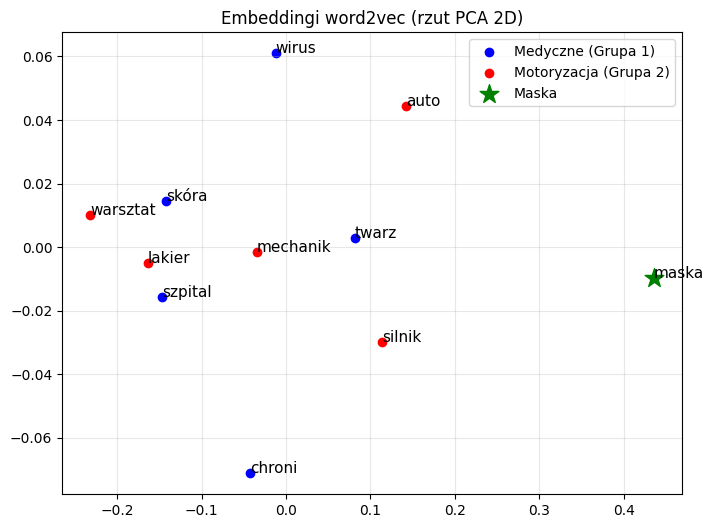

Średnie podobieństwo wewnątrz grupy 1: 0.9921
Średnie podobieństwo wewnątrz grupy 2: 0.9917
Średnie podobieństwo między grupami: 0.9916


In [7]:
from itertools import combinations

g1 = ['twarz', 'skóra', 'wirus', 'szpital', 'chroni']
g2 = ['auto', 'lakier', 'warsztat', 'mechanik', 'silnik']
slowa = g1 + g2 + ['maska']

V = np.stack([w2v_1.wv[w] for w in slowa])
XY = PCA(n_components=2, random_state=0).fit_transform(V)

plt.figure(figsize=(8,6))
plt.scatter(XY[:5,0], XY[:5,1], c='blue', label='Medyczne (Grupa 1)')
plt.scatter(XY[5:10,0], XY[5:10,1], c='red', label='Motoryzacja (Grupa 2)')
plt.scatter(XY[10,0], XY[10,1], c='green', marker='*', s=200, label='Maska')

for (x,y), w in zip(XY, slowa):
    plt.annotate(w, (x,y), fontsize=11)

plt.title('Embeddingi word2vec (rzut PCA 2D)'); plt.grid(alpha=0.3); plt.legend(); plt.show()

sim_g1 = [w2v_1.wv.similarity(a, b) for a, b in combinations(g1, 2)]
sim_g2 = [w2v_1.wv.similarity(a, b) for a, b in combinations(g2, 2)]
sim_miedzy = [w2v_1.wv.similarity(a, b) for a in g1 for b in g2]

print('Średnie podobieństwo wewnątrz grupy 1:', round(sum(sim_g1) / len(sim_g1), 4))
print('Średnie podobieństwo wewnątrz grupy 2:', round(sum(sim_g2) / len(sim_g2), 4))
print('Średnie podobieństwo między grupami:', round(sum(sim_miedzy) / len(sim_miedzy), 4))

In [8]:
print('Przykład pary wewnątrz Grupy 1 (twarz - skóra):', round(w2v_1.wv.similarity('twarz', 'skóra'), 4))
print('Przykład pary między grupami (twarz - silnik):', round(w2v_1.wv.similarity('twarz', 'silnik'), 4))

Przykład pary wewnątrz Grupy 1 (twarz - skóra): 0.9947
Przykład pary między grupami (twarz - silnik): 0.9935
